# 04 · Classification Baseline & Evaluation Metrics - MEPS HC-243 (2022)

**Goal:** set the **baseline** every later model must beat, and learn how to *judge* a classifier using every metric in the project plan, each with a chart.

| Step | What happens | Main library |
|---|---|---|
| 1 | Load the training data and fix 5 cross-validation folds | pandas, scikit-learn |
| 2 | Dummy baselines: models that don't look at the features | `sklearn.dummy` |
| 3 | First real model: logistic regression | `sklearn.linear_model` |
| 4-6 | Confusion matrix, then accuracy, precision, recall, F1 | `sklearn.metrics` |
| 7-8 | ROC curve / ROC-AUC and Precision-Recall curve / PR-AUC | `sklearn.metrics` displays |
| 9-11 | Decision threshold, score distributions, calibration | scikit-learn, Seaborn |
| 12 | Overfitting check (train vs validation) | scikit-learn |
| 13 | Handling class imbalance: class weights, over-/under-sampling, SMOTE | imbalanced-learn |

> **Only the training set is used.** All scores come from **5-fold cross-validation**: the model is trained on 4/5 of the training data and scored on the remaining 1/5, five times. The test set stays locked until notebook 07.

## Step 0 - Setup

**🛠️ What this code does:** Imports the libraries:
- **scikit-learn** for models, cross-validation, metrics and metric charts (`ConfusionMatrixDisplay`, `RocCurveDisplay`, `PrecisionRecallDisplay`, `CalibrationDisplay`).
- **imbalanced-learn** for resampling methods (oversampling, undersampling, SMOTE).
- **pandas, NumPy, Matplotlib, Seaborn** for tables and charts.
- The project's own modules from `src/`:
  - `evaluation.py` runs cross-validation and collects out-of-fold predictions.
  - `classification.py` holds the model definitions.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, roc_curve, precision_recall_curve,
                             accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, brier_score_loss)
from sklearn.calibration import CalibrationDisplay
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

from src.preprocessing import (load_split, load_selected_features, build_preprocessor, cv_folds,
                               LABEL_COL, GROUP_COL, RANDOM_STATE)
from src.classification import build, make_pipeline
from src.evaluation import evaluate_cv, summarize, metrics_at_threshold, best_f1_threshold, METRIC_LABELS
from src.visualization import (SERIES, LOW_COST_COLOR, HIGH_COST_COLOR, INK, INK_SECONDARY, INK_MUTED,
                               SURFACE, SEQUENTIAL_BLUE, apply_style, save_fig)

apply_style()
pd.set_option("display.width", 160)
RESULTS = ROOT / "reports" / "results"
SHOW = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
print("Libraries loaded.")

Libraries loaded.


## Step 1 - Load the training data and fix the cross-validation folds

> **🎓 Theory in brief**
>
> **Cross-validation (CV)** gives a reliable score *without* touching the test set. The training data is cut into 5 parts (**folds**). Each fold takes one turn as the "validation" part while the model trains on the other 4. Averaging the 5 scores gives a stable estimate, and their spread shows how much the score moves by chance.
> 
> The folds are **stratified** (each has 20% high-cost people) and **grouped** (a household is never split between training and validation). The same 5 folds are reused for every model in notebooks 04-06, so comparisons are fair.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#5-cross-validation)*

**🛠️ What this code does:** Loads `train.parquet` and the 37 features chosen in notebook 03, separates inputs (`X`), target (`y`) and household IDs (`groups`), then creates the 5 fixed folds and shows each fold's size and high-cost rate. It deliberately never opens `test.parquet`.

In [2]:
train, _ = load_split()          # the test part is deliberately ignored
features = load_selected_features()
X, y, groups = train[features], train[LABEL_COL], train[GROUP_COL]
folds = cv_folds(X, y, groups)

fold_table = pd.DataFrame([{
    "fold": i + 1, "train rows": len(tr), "validation rows": len(va),
    "validation high-cost rate": y.iloc[va].mean(),
    "households in both": len(set(groups.iloc[tr]) & set(groups.iloc[va])),
} for i, (tr, va) in enumerate(folds)])
print(f"Training data: {len(X):,} people, {X.shape[1]} features, high-cost rate {y.mean():.1%}")
display(fold_table.style.format({"validation high-cost rate": "{:.1%}"}))

Training data: 17,398 people, 37 features, high-cost rate 20.0%


,fold,train rows,validation rows,validation high-cost rate,households in both
0,1,13919,3479,20.0%,0
1,2,13918,3480,20.0%,0
2,3,13918,3480,20.0%,0
3,4,13918,3480,20.0%,0
4,5,13919,3479,20.0%,0


**📖 What the result shows:**
Each fold trains on about 13,900 people and validates on about 3,480. Every validation fold has **20% high-cost people** and **no household appears on both sides**. These are the 5 "mini test sets" behind every score in this notebook.

**🛠️ What this code does:** Builds the preprocessing pipeline from notebook 03 for the 37 selected features. It also computes the **class ratio**, low-cost ÷ high-cost (≈ 4). Some models use this ratio to give the rarer class more weight.

In [3]:
preprocessor = build_preprocessor(features)
n_encoded = preprocessor.fit(X).transform(X).shape[1]     # fitted here only to count columns
pos_weight = float((y == 0).sum() / (y == 1).sum())
print(f"Encoded columns after preprocessing: {n_encoded}")
print(f"Class ratio (low-cost : high-cost) = {pos_weight:.2f} : 1")

Encoded columns after preprocessing: 110
Class ratio (low-cost : high-cost) = 4.00 : 1


**📖 What the result shows:**
The 37 features become **110 encoded columns**. There are 4 low-cost people for every high-cost person. That imbalance shapes almost every result below.

## Step 2 - Dummy baselines: what does "no skill" look like?

> **🎓 Theory in brief**
>
> A **baseline** is the simplest possible "model". If a real model can't beat it, the model has learned nothing.
> - **Most frequent:** always predicts the majority class, "low cost".
> - **Stratified random:** guesses "high cost" at random for 20% of people, ignoring their features.
> 
> Neither looks at the data, so they show what scores *pure chance* produces.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Runs both dummy classifiers through the same 5-fold cross-validation as the real models and shows the average of each metric.

In [4]:
results = {}
for name in ["Dummy (most frequent)", "Dummy (stratified random)"]:
    model, sampler = build("Baseline", name, pos_weight)
    results[name] = evaluate_cv(make_pipeline(preprocessor, model, sampler), X, y, folds, n_jobs=5)
display(summarize(results)[SHOW].astype(float).round(3).rename(columns=METRIC_LABELS))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy (most frequent),0.80,0.500,0.000,0.000,0.000,0.500,0.2
Dummy (stratified random),0.68,0.499,0.199,0.198,0.199,0.499,0.2


**📖 What the result shows:**
This table is the most important lesson of the notebook:

- The **"always low cost"** model is **80% accurate** while finding **zero** high-cost people (recall 0, F1 0). Accuracy looks great only because 80% of people *are* low-cost.
- **Random guessing** gets 68% accuracy, but recall, precision and F1 are all about 0.20, which is just the base rate.
- Both have **ROC-AUC = 0.50**, the value for "no ability to rank people". PR-AUC ≈ **0.20**, the value for "no better than the base rate".

**So a model must clearly beat:** accuracy 0.80, F1 0.20, ROC-AUC 0.50 and PR-AUC 0.20. This is why the project judges models on ROC-AUC, PR-AUC, recall and F1, not accuracy.

## Step 3 - First real model: logistic regression

> **🎓 Theory in brief**
>
> **Logistic regression** gives each feature a weight, adds them up into a score *z*, and squeezes the score into a probability between 0 and 1 with the **sigmoid** function: p = 1 / (1 + e^(-z)). If p ≥ 0.5 the person is predicted "high cost".
> 
> `class_weight="balanced"` tells the model that mistakes on the rarer high-cost class cost 4 times more, so it doesn't simply ignore that class.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#101-logistic-regression)*

**🛠️ What this code does:** Trains logistic regression (L2 penalty, balanced class weights) inside the full pipeline, preprocessing included, on each of the 5 folds. It shows the validation score on every fold and their mean ± standard deviation.

In [5]:
model, sampler = build("Logistic Regression", "L2 + balanced", pos_weight)
lr = evaluate_cv(make_pipeline(preprocessor, model, sampler), X, y, folds, n_jobs=5)
results["Logistic Regression"] = lr

per_fold = lr.folds[[f"test_{m}" for m in SHOW]].copy()
per_fold.columns = [METRIC_LABELS[m] for m in SHOW]
per_fold.index = [f"fold {i+1}" for i in range(len(per_fold))]
per_fold.loc["mean"] = per_fold.mean()
per_fold.loc["std"] = per_fold.iloc[:5].std()
display(per_fold.round(3))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
fold 1,0.757,0.742,0.435,0.716,0.541,0.819,0.561
fold 2,0.757,0.749,0.436,0.737,0.548,0.826,0.584
fold 3,0.752,0.736,0.428,0.710,0.534,0.819,0.557
fold 4,0.754,0.745,0.432,0.731,0.543,0.820,0.551
fold 5,0.759,0.747,0.439,0.726,0.547,0.826,0.575
mean,0.756,0.744,0.434,0.724,0.543,0.822,0.566
std,0.003,0.005,0.004,0.011,0.006,0.004,0.014


**📖 What the result shows:**
Logistic regression beats both baselines by a wide margin:

- **ROC-AUC 0.822** (baseline 0.50): pick one random high-cost and one random low-cost person, and the model gives the high-cost one the higher score 82% of the time.
- **Recall 0.724:** it catches about **72% of high-cost people**.
- **Precision 0.434:** of the people it flags, **43% really are high-cost**. That is more than double the 20% that random flagging would give.
- **F1 0.543** and **PR-AUC 0.566**, against 0.20 for the baselines.
- **Accuracy 0.756** is actually *lower* than the dummy's 0.80, yet this model is far more useful. That is one more sign that accuracy is the wrong yardstick here.

The five folds agree closely (ROC-AUC std 0.004), so these numbers are stable rather than the luck of one particular split.

## Step 4 - The confusion matrix

> **🎓 Theory in brief**
>
> Every prediction falls into one of four boxes:
> 
> | | Predicted low cost | Predicted high cost |
> |---|---|---|
> | **Actually low cost** | **True Negative (TN):** correctly left alone | **False Positive (FP):** a false alarm |
> | **Actually high cost** | **False Negative (FN):** a missed high-cost person | **True Positive (TP):** correctly flagged |
> 
> Every classification metric is built from these four numbers.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Builds confusion matrices from **out-of-fold predictions**: each person's prediction comes from the fold model that did *not* see them during training, so all 17,398 training people get one honest prediction. It shows three panels: the "always low cost" dummy, logistic regression in counts, and logistic regression as percentages of each true class.

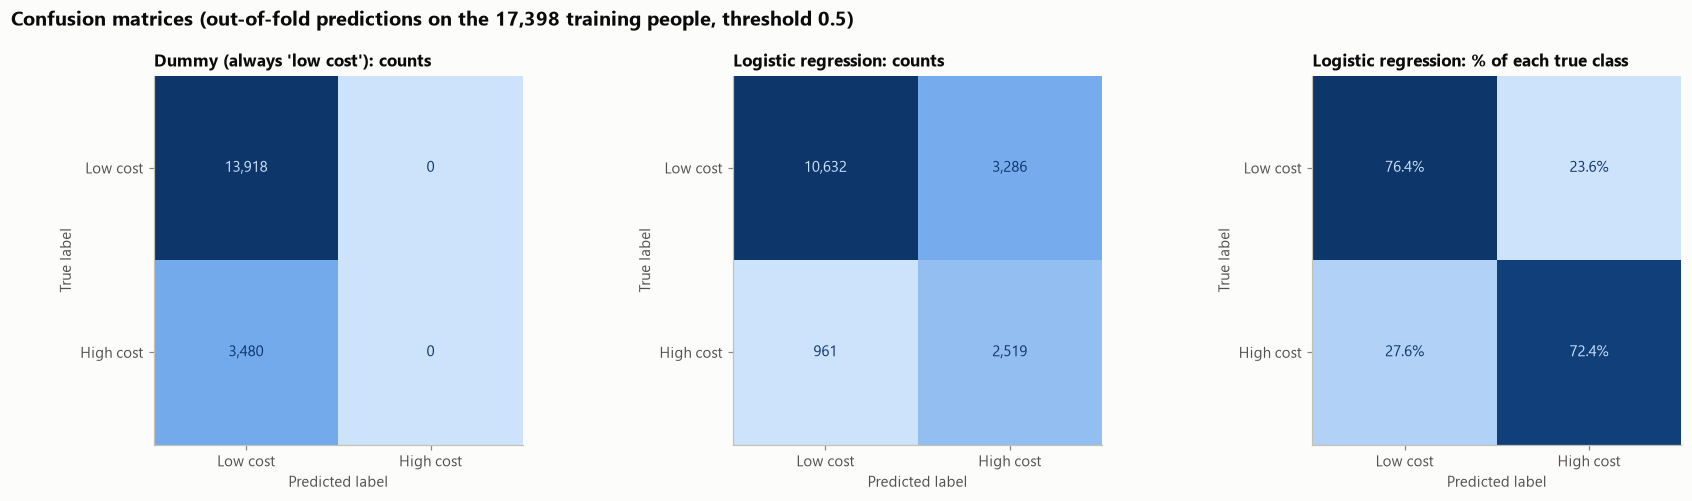

Logistic regression: TN=10,632  FP=3,286  FN=961  TP=2,519


In [6]:
labels = ["Low cost", "High cost"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
panels = [(results["Dummy (most frequent)"].oof_pred, None, "Dummy (always 'low cost'): counts"),
          (lr.oof_pred, None, "Logistic regression: counts"),
          (lr.oof_pred, "true", "Logistic regression: % of each true class")]
for ax, (pred, norm, title) in zip(axes, panels):
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=labels, normalize=norm, cmap=SEQUENTIAL_BLUE,
                                            values_format=".1%" if norm else ",d", colorbar=False, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.grid(False)
fig.suptitle("Confusion matrices (out-of-fold predictions on the 17,398 training people, threshold 0.5)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_confusion_matrices")
plt.show()

tn, fp, fn, tp = confusion_matrix(y, lr.oof_pred).ravel()
print(f"Logistic regression: TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

#### 📖 What this chart shows (in plain English)
The rows are the **truth** and the columns are the **prediction**. Darker squares hold more people.

**Left (dummy):** everyone is predicted "low cost". It is right about the 13,918 low-cost people, but **all 3,480 high-cost people are missed**.

**Middle (logistic regression, counts):**
- **TN = 10,632** low-cost people correctly left alone.
- **FP = 3,286** false alarms (low-cost people flagged).
- **FN = 961** high-cost people missed.
- **TP = 2,519** high-cost people correctly flagged.

**Right (percent of each true class):** the model catches **72.4%** of high-cost people (recall) and correctly leaves **76.4%** of low-cost people alone (specificity). 23.6% of low-cost people get a false alarm.

**Why are there more false alarms than correct catches?** There are 4 times as many low-cost people, so even a moderate false-alarm *rate* (23.6%) produces more false alarms (3,286) than true catches (2,519). This is normal with imbalanced data, and it is why precision is only 0.43.

## Step 5 - The metrics, calculated by hand

**🛠️ What this code does:** Calculates each metric **by hand** from the four confusion-matrix numbers, then checks the result against scikit-learn's own function. This makes clear that every metric is simple arithmetic on TP, FP, TN and FN.

In [7]:
by_hand = {
    "Accuracy":          ("(TP + TN) / all",            (tp + tn) / (tp + tn + fp + fn), accuracy_score(y, lr.oof_pred)),
    "Precision":         ("TP / (TP + FP)",             tp / (tp + fp),                  precision_score(y, lr.oof_pred)),
    "Recall (TPR)":      ("TP / (TP + FN)",             tp / (tp + fn),                  recall_score(y, lr.oof_pred)),
    "Specificity (TNR)": ("TN / (TN + FP)",             tn / (tn + fp),                  recall_score(y, lr.oof_pred, pos_label=0)),
    "F1":                ("2·P·R / (P + R)",            2 * tp / (2 * tp + fp + fn),     f1_score(y, lr.oof_pred)),
    "Balanced accuracy": ("(Recall + Specificity) / 2", (tp / (tp + fn) + tn / (tn + fp)) / 2,
                          balanced_accuracy_score(y, lr.oof_pred)),
}
display(pd.DataFrame(by_hand, index=["formula", "by hand", "scikit-learn"]).T.style.format(
    {"by hand": "{:.4f}", "scikit-learn": "{:.4f}"}))

,formula,by hand,scikit-learn
Accuracy,(TP + TN) / all,0.7559,0.7559
Precision,TP / (TP + FP),0.4339,0.4339
Recall (TPR),TP / (TP + FN),0.7239,0.7239
Specificity (TNR),TN / (TN + FP),0.7639,0.7639
F1,2·P·R / (P + R),0.5426,0.5426
Balanced accuracy,(Recall + Specificity) / 2,0.7439,0.7439


**📖 What the result shows:**
Every hand calculation matches scikit-learn exactly. In plain words:

| Metric | Value | Meaning here |
|---|---|---|
| Accuracy | 0.756 | 76% of all predictions are right |
| Precision | 0.434 | Of the people flagged, 43% really are high-cost |
| Recall | 0.724 | The model catches 72% of high-cost people |
| Specificity | 0.764 | It correctly leaves 76% of low-cost people alone |
| F1 | 0.543 | Combines precision and recall. It is high only when *both* are high |
| Balanced accuracy | 0.744 | Average of recall and specificity. Unlike accuracy, it isn't fooled by imbalance: the "always low cost" dummy scores only 0.50 |

These values come from pooling all out-of-fold predictions, which is why they are nearly identical to the fold averages in Step 3.

## Step 6 - ROC curve and ROC-AUC

> **🎓 Theory in brief**
>
> The model really outputs a **probability**, and 0.5 is just one possible cut-off. The **ROC curve** tries *every* cut-off and plots:
> - **x-axis, False Positive Rate:** the share of low-cost people wrongly flagged.
> - **y-axis, True Positive Rate (recall):** the share of high-cost people caught.
> 
> **ROC-AUC** is the area under that curve. It equals the probability that a randomly chosen high-cost person gets a *higher* score than a randomly chosen low-cost person:
> - 0.5 means random ranking.
> - 1.0 means perfect ranking.
> - 0.8 to 0.9 is usually called "good".
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Draws the ROC curve of logistic regression (from out-of-fold probabilities) and of the random dummy, plus the diagonal "chance" line. It marks the point the default 0.5 threshold gives.

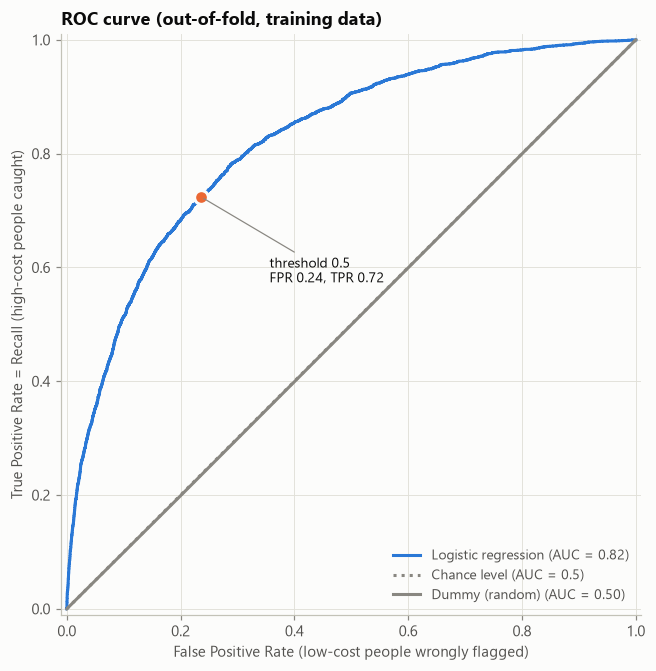

In [8]:
fig, ax = plt.subplots(figsize=(7, 6.2))
RocCurveDisplay.from_predictions(y, lr.oof_scores, name="Logistic regression", curve_kwargs={"color": LOW_COST_COLOR}, ax=ax,
                                 plot_chance_level=True, chance_level_kw={"color": INK_MUTED, "linestyle": ":"})
RocCurveDisplay.from_predictions(y, results["Dummy (stratified random)"].oof_scores, name="Dummy (random)",
                                 curve_kwargs={"color": INK_MUTED}, ax=ax)
fpr05 = fp / (fp + tn); tpr05 = tp / (tp + fn)
ax.plot(fpr05, tpr05, "o", color=HIGH_COST_COLOR, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"threshold 0.5\nFPR {fpr05:.2f}, TPR {tpr05:.2f}", (fpr05, tpr05), xytext=(fpr05 + 0.12, tpr05 - 0.15),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.8))
ax.set_xlabel("False Positive Rate (low-cost people wrongly flagged)")
ax.set_ylabel("True Positive Rate = Recall (high-cost people caught)")
ax.set_title("ROC curve (out-of-fold, training data)")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save_fig(fig, "04_roc_curve")
plt.show()

#### 📖 What this chart shows (in plain English)
- The **blue curve** (logistic regression) bows far above the diagonal, with **AUC = 0.82**. The **grey line** (random dummy) lies on the diagonal, AUC = 0.50: random guessing catches high-cost people only as fast as it creates false alarms.
- Each point on the blue curve is one threshold. The **orange dot** is the default 0.5: it catches **72%** of high-cost people (TPR 0.72) at the price of flagging **24%** of low-cost people (FPR 0.24). Moving right along the curve catches more high-cost people but adds more false alarms.
- The **steep start** on the left means the people the model is most confident about are almost all truly high-cost.

## Step 7 - Precision-Recall curve and PR-AUC

> **🎓 Theory in brief**
>
> When the positive class is rare, the ROC curve can look flattering, because its x-axis divides by the *large* number of low-cost people. The **Precision-Recall (PR) curve** focuses only on the high-cost class:
> - **x-axis, recall:** how many high-cost people we catch.
> - **y-axis, precision:** of the people we flag, how many really are high-cost.
> 
> **PR-AUC** (average precision) summarises it. A no-skill model scores the base rate, 0.20 here.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Draws the precision-recall curve of logistic regression, the 0.20 no-skill line, and the point given by the 0.5 threshold.

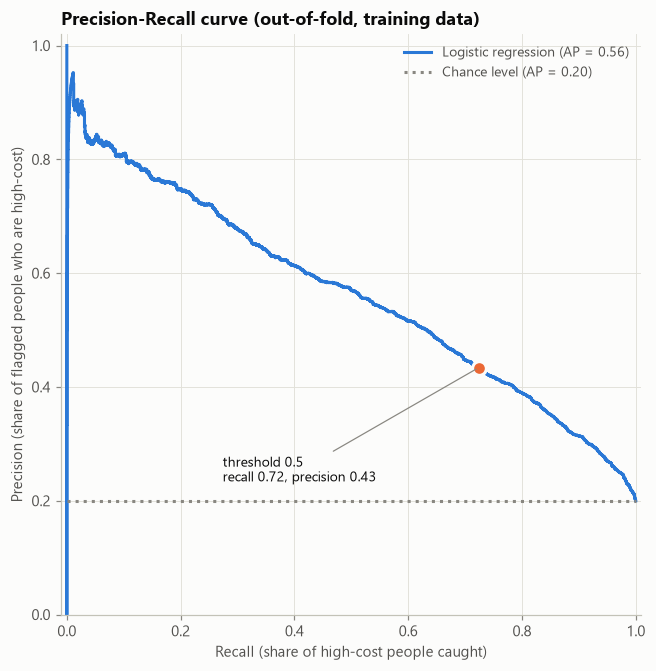

In [9]:
fig, ax = plt.subplots(figsize=(7, 6.2))
PrecisionRecallDisplay.from_predictions(y, lr.oof_scores, name="Logistic regression",
                                        curve_kwargs={"color": LOW_COST_COLOR}, ax=ax,
                                        plot_chance_level=True,
                                        chance_level_kw={"color": INK_MUTED, "linestyle": ":"})
p05, r05 = tp / (tp + fp), tp / (tp + fn)
ax.plot(r05, p05, "o", color=HIGH_COST_COLOR, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"threshold 0.5\nrecall {r05:.2f}, precision {p05:.2f}", (r05, p05), xytext=(r05 - 0.45, p05 - 0.2),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.8))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall (share of high-cost people caught)")
ax.set_ylabel("Precision (share of flagged people who are high-cost)")
ax.set_title("Precision-Recall curve (out-of-fold, training data)")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, "04_precision_recall_curve")
plt.show()

#### 📖 What this chart shows (in plain English)
- On the **left**, among the people with the highest scores, **80-90% really are high-cost**. The jagged bit at the far left is noise from the first handful of people.
- Moving **right** (lowering the bar to catch more people), precision falls steadily. When *everyone* is flagged (recall = 1), it reaches 0.20, the base rate.
- At **threshold 0.5:** recall 0.72 and precision 0.43.
- **AP (PR-AUC) = 0.56**, almost 3 times the no-skill line at 0.20.

PR-AUC is the stricter metric. It shows that finding high-cost people is still hard: even at moderate recall, many of the people flagged are false alarms. Model comparisons will use PR-AUC alongside ROC-AUC.

## Step 8 - Choosing the decision threshold

> **🎓 Theory in brief**
>
> A classifier gives a *score*, and the **threshold** turns it into a yes/no decision.
> - A **lower** threshold flags more people: recall goes up, precision goes down.
> - A **higher** threshold flags fewer people: precision goes up, recall goes down.
> 
> Which balance is right depends on the cost of each mistake. Missing a high-cost person might mean no early support; a false alarm might mean an unnecessary follow-up. The F1 score balances the two equally. The final threshold will be chosen in notebook 07, on training data only.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Plots precision, recall and F1 for every threshold from 0 to 1, marks the default 0.5 and the threshold with the best F1, and prints a table of the metrics at a few thresholds.

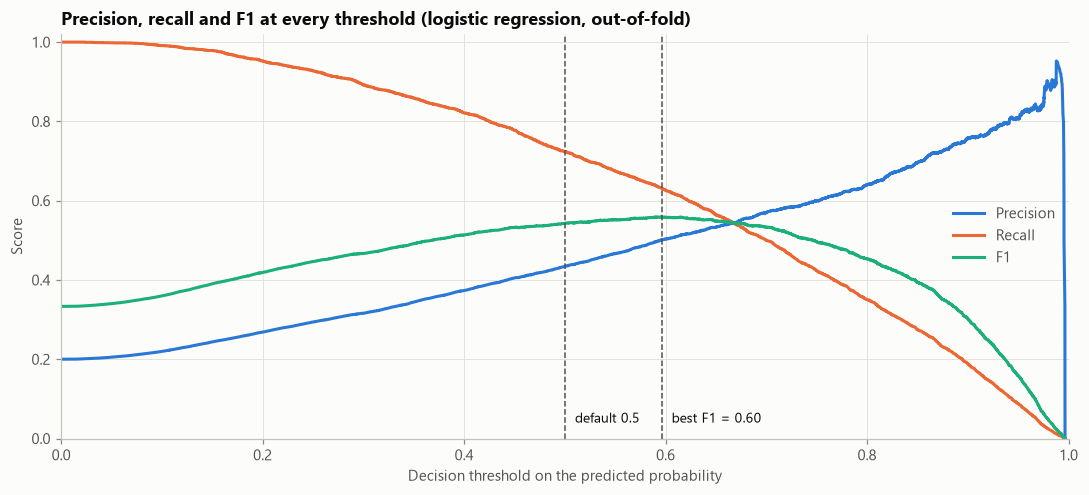

,accuracy,precision,recall,f1,people flagged
threshold,,,,,
0.300000,0.592,0.316,0.892,0.467,9820
0.500000,0.756,0.434,0.724,0.543,5805
0.596002,0.801,0.501,0.632,0.559,4390
0.700000,0.824,0.570,0.500,0.533,3055
0.800000,0.831,0.640,0.351,0.453,1907


In [10]:
prec, rec, thr = precision_recall_curve(y, lr.oof_scores)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
best_thr = best_f1_threshold(y, lr.oof_scores)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(thr, prec[:-1], color=LOW_COST_COLOR, label="Precision")
ax.plot(thr, rec[:-1], color=HIGH_COST_COLOR, label="Recall")
ax.plot(thr, f1[:-1], color=SERIES[2], label="F1")
for t, name in [(0.5, "default 0.5"), (best_thr, f"best F1 = {best_thr:.2f}")]:
    ax.axvline(t, color=INK_SECONDARY, linestyle="--", linewidth=1)
    ax.text(t + 0.01, 0.04, name, fontsize=9, color=INK)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Decision threshold on the predicted probability")
ax.set_ylabel("Score")
ax.legend(loc="center right")
ax.set_title("Precision, recall and F1 at every threshold (logistic regression, out-of-fold)")
fig.tight_layout()
save_fig(fig, "04_threshold_tradeoff")
plt.show()

rows = [metrics_at_threshold(y, lr.oof_scores, t) for t in [0.3, 0.5, best_thr, 0.7, 0.8]]
for r in rows:
    r["people flagged"] = int((lr.oof_scores >= r["threshold"]).sum())
display(pd.DataFrame(rows).set_index("threshold").drop(columns=["roc_auc", "pr_auc"]).round(3))

#### 📖 What this chart shows (in plain English)
As the threshold rises (moving right), **recall** (orange) falls and **precision** (blue) rises. **F1** (green) peaks in between.

| Threshold | People flagged | Recall | Precision | F1 |
|---|---|---|---|---|
| 0.30 | 9,820 (56% of everyone) | 0.89 | 0.32 | 0.47 |
| 0.50 (default) | 5,805 | 0.72 | 0.43 | 0.54 |
| **0.60 (best F1)** | 4,390 | 0.63 | 0.50 | **0.56** |
| 0.70 | 3,055 | 0.50 | 0.57 | 0.53 |
| 0.80 | 1,907 | 0.35 | 0.64 | 0.45 |

- The F1 curve is fairly **flat between about 0.45 and 0.65**, so for F1 the exact threshold isn't critical.
- The *right* threshold depends on the use. A program that must not miss anyone would choose a low threshold (high recall). A program with a small budget would choose a high threshold (high precision).
- The final threshold is chosen in notebook 07, using training data only.

## Step 9 - How well are the two classes separated?

**🛠️ What this code does:** Draws the distribution of predicted probabilities separately for people who were *really* low-cost (blue) and *really* high-cost (orange). A good model pushes the two humps apart.

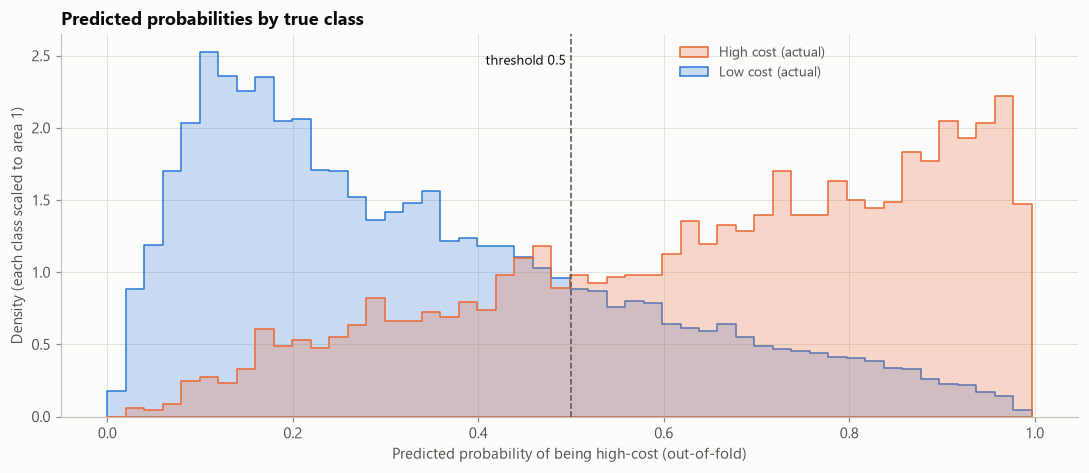

Median predicted probability: low-cost 0.29, high-cost 0.70


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.4))
plot_df = pd.DataFrame({"score": lr.oof_scores, "class": np.where(y == 1, "High cost (actual)", "Low cost (actual)")})
sns.histplot(data=plot_df, x="score", hue="class", bins=50, stat="density", common_norm=False, element="step",
             fill=True, alpha=0.25, palette={"Low cost (actual)": LOW_COST_COLOR, "High cost (actual)": HIGH_COST_COLOR},
             ax=ax)
sns.move_legend(ax, "upper center", bbox_to_anchor=(0.68, 1.0), title=None, fontsize=9)
ax.axvline(0.5, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(0.495, ax.get_ylim()[1] * 0.92, "threshold 0.5", fontsize=9, ha="right")
ax.set_xlabel("Predicted probability of being high-cost (out-of-fold)")
ax.set_ylabel("Density (each class scaled to area 1)")
ax.set_title("Predicted probabilities by true class")
fig.tight_layout()
save_fig(fig, "04_score_distributions")
plt.show()
print(f"Median predicted probability: low-cost {np.median(lr.oof_scores[y == 0]):.2f}, "
      f"high-cost {np.median(lr.oof_scores[y == 1]):.2f}")

#### 📖 What this chart shows (in plain English)
- Most **low-cost people** (blue) get low probabilities (median **0.29**), and most **high-cost people** (orange) get high ones (median **0.70**). The model does separate the two groups.
- But the humps **overlap a lot between about 0.3 and 0.7**. These people look alike on paper, with similar age and conditions, yet ended up on different sides of the $8,913 line.
- That overlap is why no threshold gives both high precision *and* high recall, and why ROC-AUC is 0.82 rather than 0.95+. Part of healthcare cost is genuinely unpredictable from survey answers: accidents, sudden illnesses, a single hospital stay.

(The probabilities lean high overall, with low-cost people at a median of 0.29 rather than near 0. That comes from the class weighting, explained in the next step.)

## Step 10 - Calibration: can the probabilities be trusted?

> **🎓 Theory in brief**
>
> A model is **well calibrated** if, among people given a 30% probability, about 30% really are high-cost. The **calibration curve** (reliability diagram) plots predicted probability against the actual rate; a perfect model follows the diagonal. The **Brier score** is the mean squared error of the probabilities, where lower is better.
> 
> Class weighting and resampling help the model notice the rare class, but they **inflate** the probabilities. Ranking (ROC-AUC) is unaffected, but the numbers stop being true probabilities.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#12-evaluation-metrics-for-classification)*

**🛠️ What this code does:** Also trains logistic regression **without** class weights, then draws calibration curves for both versions and prints their Brier scores and ROC-AUC.

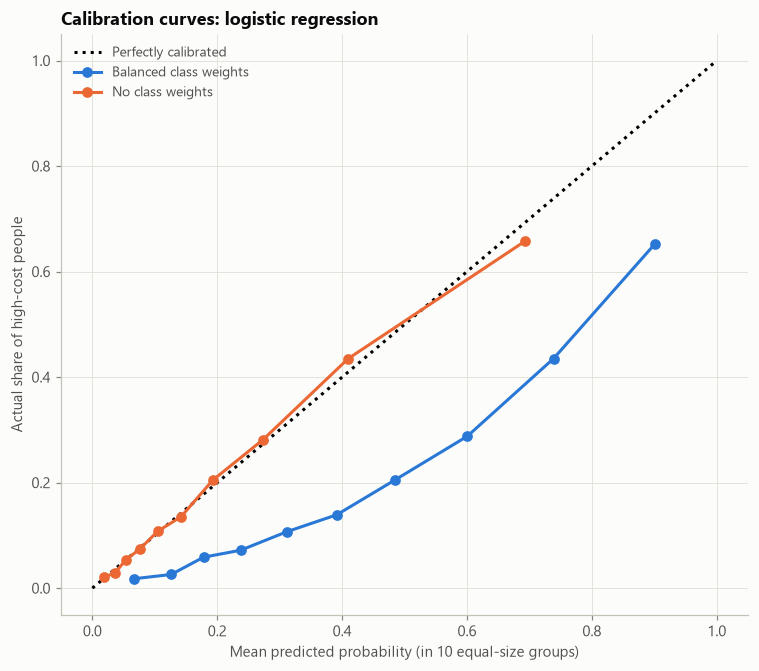

,Brier score (lower = better),ROC-AUC,Recall @0.5,Mean predicted probability
Balanced class weights,0.17,0.822,0.724,0.404
No class weights,0.12,0.822,0.340,0.200


In [12]:
model, sampler = build("Logistic Regression", "L2, no class weight", pos_weight)
lr_plain = evaluate_cv(make_pipeline(preprocessor, model, sampler), X, y, folds, n_jobs=5)

fig, ax = plt.subplots(figsize=(7, 6.2))
for res, name, color in [(lr, "Balanced class weights", LOW_COST_COLOR), (lr_plain, "No class weights", HIGH_COST_COLOR)]:
    CalibrationDisplay.from_predictions(y, res.oof_scores, n_bins=10, strategy="quantile", name=name,
                                        color=color, ax=ax, marker="o")
ax.set_xlabel("Mean predicted probability (in 10 equal-size groups)")
ax.set_ylabel("Actual share of high-cost people")
ax.set_title("Calibration curves: logistic regression")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save_fig(fig, "04_calibration")
plt.show()

display(pd.DataFrame({
    "Brier score (lower = better)": [brier_score_loss(y, lr.oof_scores), brier_score_loss(y, lr_plain.oof_scores)],
    "ROC-AUC": [lr.folds.test_roc_auc.mean(), lr_plain.folds.test_roc_auc.mean()],
    "Recall @0.5": [lr.folds.test_recall.mean(), lr_plain.folds.test_recall.mean()],
    "Mean predicted probability": [lr.oof_scores.mean(), lr_plain.oof_scores.mean()],
}, index=["Balanced class weights", "No class weights"]).round(3))

#### 📖 What this chart shows (in plain English)
- **Orange (no class weights)** follows the diagonal closely. When it says "40%", about 40-43% of those people really are high-cost, so its probabilities can be trusted. Brier score **0.12**.
- **Blue (balanced class weights)** lies well *below* the diagonal. When it says "60%", only about 29% really are high-cost. Its probabilities are **inflated**: the average prediction is 0.40, while the real rate is 0.20. Brier score **0.17**.
- Yet **ROC-AUC is identical (0.822)**. Both models put people in the *same order*; weighting only stretches the probability scale.
- Recall at 0.5 differs hugely (0.72 vs 0.34), because the same 0.5 cut lands in a different place on each scale.

**Takeaway:** class weights are useful when a fixed 0.5 cut-off is used. If the app should show a meaningful "risk %", use an unweighted or **calibrated** model (scikit-learn's `CalibratedClassifierCV`). This is revisited in notebook 07.

## Step 11 - Overfitting check: training score vs validation score

> **🎓 Theory in brief**
>
> **Overfitting** means a model memorises the training data instead of learning general patterns. It shows up as a **large gap** between the score on the data it trained on and the score on unseen validation data. **Underfitting** means both scores are low. A small gap with a good validation score is the goal.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#11-overfitting-underfitting-and-the-bias-variance-trade-off)*

**🛠️ What this code does:** Compares the average score on the training folds with the average score on the validation folds for logistic regression.

In [13]:
gap = pd.DataFrame({
    "training folds": [lr.folds[f"train_{m}"].mean() for m in SHOW],
    "validation folds": [lr.folds[f"test_{m}"].mean() for m in SHOW],
}, index=[METRIC_LABELS[m] for m in SHOW])
gap["gap"] = gap["training folds"] - gap["validation folds"]
display(gap.round(4))

,training folds,validation folds,gap
Accuracy,0.7593,0.7559,0.0034
Balanced accuracy,0.7501,0.7439,0.0062
Precision,0.4393,0.4339,0.0053
Recall,0.7348,0.7239,0.0109
F1,0.5498,0.5426,0.0072
ROC-AUC,0.8284,0.8222,0.0061
PR-AUC,0.5726,0.5655,0.0070


**📖 What the result shows:**
Training and validation scores differ by **less than 0.011 on every metric** (ROC-AUC 0.828 vs 0.822). Logistic regression is a simple model, about 110 weights learned from about 14,000 people, so it cannot memorise individuals. **It does not overfit.**

If anything, it may *underfit*: it is too simple to capture interactions such as "old *and* several conditions". The more flexible models in notebook 05 will test whether that matters.

## Step 12 - Handling class imbalance

> **🎓 Theory in brief**
>
> With 80% low-cost people, a model can look accurate while ignoring the high-cost class. Common fixes:
> 
> | Method | What it does |
> |---|---|
> | **Class weights** | Mistakes on the rare class count more in training. No rows are added or removed. |
> | **Random oversampling** | Copies random high-cost rows until the classes are equal. |
> | **Random undersampling** | Throws away random low-cost rows until the classes are equal. |
> | **SMOTE** | Creates *new synthetic* high-cost rows by mixing each one with its nearest high-cost neighbours. |
> 
> **Resampling must only touch the training folds.** Validation and test data must keep the real 80/20 mix, otherwise the scores are fake. imbalanced-learn's `Pipeline` guarantees this, because the sampler only runs during `fit`.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#9-imbalanced-classification)*

**🛠️ What this code does:** Trains logistic regression five ways (no fix, class weights, random oversampling, random undersampling, SMOTE) on the same folds. Resampling happens *inside* each training fold only. It then compares the metrics in a table and a chart.

,Recall,Precision,F1,Balanced accuracy,ROC-AUC,PR-AUC,Accuracy
No fix,0.340,0.649,0.446,0.647,0.822,0.567,0.831
Class weights,0.724,0.434,0.543,0.744,0.822,0.566,0.756
Random oversampling,0.723,0.433,0.541,0.743,0.822,0.565,0.755
Random undersampling,0.724,0.431,0.541,0.743,0.821,0.561,0.754
SMOTE,0.728,0.424,0.536,0.741,0.818,0.558,0.748


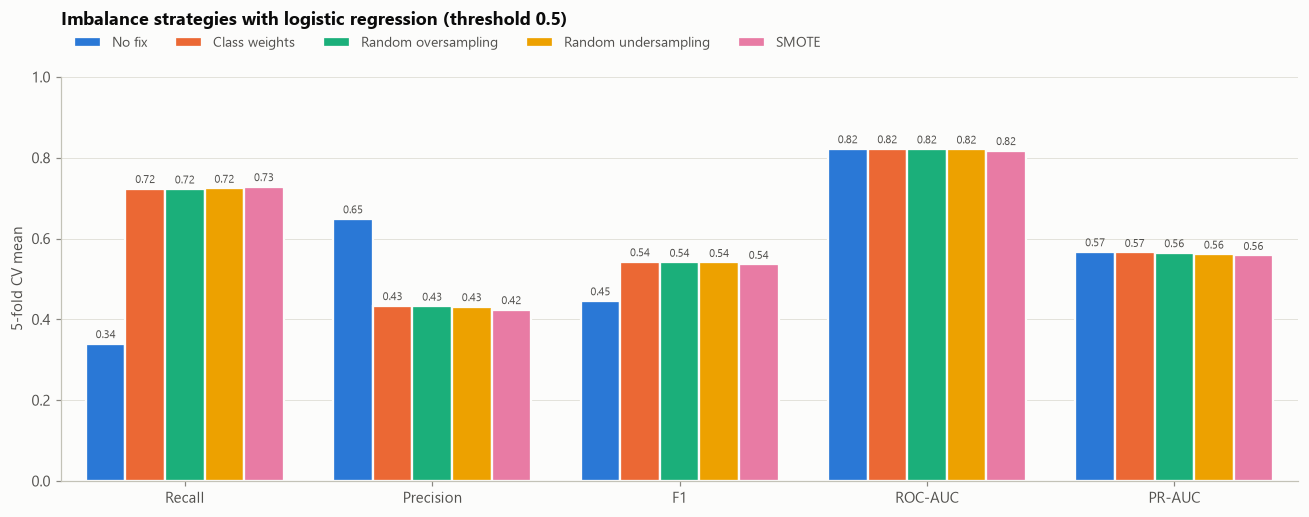

In [14]:
strategies = {
    "No fix": (LogisticRegression(max_iter=5000), None),
    "Class weights": (LogisticRegression(max_iter=5000, class_weight="balanced"), None),
    "Random oversampling": (LogisticRegression(max_iter=5000), RandomOverSampler(random_state=RANDOM_STATE)),
    "Random undersampling": (LogisticRegression(max_iter=5000), RandomUnderSampler(random_state=RANDOM_STATE)),
    "SMOTE": (LogisticRegression(max_iter=5000), SMOTE(random_state=RANDOM_STATE)),
}
imb = {name: evaluate_cv(make_pipeline(preprocessor, m, s), X, y, folds, n_jobs=5, train_score=False)
       for name, (m, s) in strategies.items()}
imb_table = summarize(imb)[["recall", "precision", "f1", "balanced_accuracy", "roc_auc", "pr_auc", "accuracy"]].astype(float)
imb_table.round(4).to_csv(RESULTS / "imbalance_strategies.csv")
display(imb_table.round(3).rename(columns=METRIC_LABELS))

long = imb_table[["recall", "precision", "f1", "roc_auc", "pr_auc"]].rename(columns=METRIC_LABELS).reset_index(
    names="strategy").melt(id_vars="strategy", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.barplot(data=long, x="metric", y="score", hue="strategy", palette=SERIES[:5], saturation=1,
            edgecolor=SURFACE, linewidth=1.5, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7.5, color=INK_SECONDARY, padding=2)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("5-fold CV mean")
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.13), fontsize=9)
ax.set_title("Imbalance strategies with logistic regression (threshold 0.5)", pad=34)
fig.tight_layout()
save_fig(fig, "04_imbalance_strategies")
plt.show()

#### 📖 What this chart shows (in plain English)
- **No fix (blue):** highest precision (0.65) and accuracy (0.83), but recall is only **0.34**, so it misses two-thirds of high-cost people.
- **All four fixes** give almost the same result: recall ≈ **0.72**, precision ≈ **0.43**, F1 ≈ **0.54**.
- **ROC-AUC and PR-AUC barely change** (0.818-0.822) across all five. The fixes don't make the model better at *ranking* people. They shift where the 0.5 cut-off falls, which is the same effect as lowering the threshold on the no-fix model (Step 8).
- **SMOTE** is slightly worse on every metric. It creates synthetic people by blending neighbours, and blending one-hot 0/1 columns produces unrealistic people, for example someone "half insured". SMOTENC is the SMOTE variant designed for categorical data.

**Decision:** use **class weights**. They give the same benefit with no extra rows, no synthetic data and the fastest training. They are applied to every model that supports them (logistic regression, trees, forests, SVM, HistGradientBoosting, and `scale_pos_weight` in XGBoost).

## Summary

| Model (5-fold CV, training data) | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Dummy: always "low cost" | 0.800 | 0.000 | 0.000 | 0.000 | 0.500 | 0.200 |
| Dummy: random guess | 0.680 | 0.199 | 0.198 | 0.199 | 0.499 | 0.200 |
| **Logistic regression (balanced)** | 0.756 | 0.434 | 0.724 | 0.543 | **0.822** | **0.566** |

**What we learned:**
1. **Accuracy is misleading** with 80/20 classes. A useless model scores 0.80.
2. **ROC-AUC and PR-AUC** judge ranking skill *independent of the threshold*, so they are the main comparison metrics. **Recall, precision and F1** describe behaviour at a chosen threshold.
3. The **threshold** is a business decision. F1 peaks around 0.60 for this model.
4. **Class weights** fix the 0.5-threshold problem as well as resampling does, but they inflate probabilities, so probabilities need **calibration** if they are shown as "risk %".
5. Logistic regression **doesn't overfit** (train-validation gap < 0.011).

**The baseline to beat: ROC-AUC 0.822, PR-AUC 0.566, F1 0.543.**

**Next:** `05_classification_algorithms.ipynb` tries every algorithm in the project plan, with its variants.